# AuditAI Senado — Experimento 1: classificação de temas com todos os algoritmos (N2)

**Projeto:** AuditAI Senado: Transparência e Análise Parlamentar com IA · **Disciplina:** Inteligência Artificial (7º CC, Mackenzie) · **Prof.:** Ivan Carlos Alcântara de Oliveira

**Integrantes:** Julia Vitória Bomfim do Nascimento (10425604), William Saran dos Santos Junior (10420128)

**Histórico:** 20/11/2026 — William Saran dos Santos Junior — criação do notebook (N2).

## Objetivo
Aplicar ao *dataset* do Senado a metodologia do notebook de estudo da Parte III (`IA_AprendizadoClass_Todos`): comparar **KNN, CART, Regressão Logística, Naive Bayes, SVM, Random Forest e AdaBoost** com **validação cruzada estratificada de 10 folds** (mesmos folds para todos), seleção de atributos dentro do `Pipeline` (sem vazamento), teste final reservado e busca de hiperparâmetros só nos dados de desenvolvimento.

## Tarefa
*Dado um discurso, ele aborda o tema T?* Os rótulos são **fracos**: o discurso é positivo se contém algum termo relacionado ao tema (lista da sondagem léxica da N1). Para que a tarefa não seja trivial (achar a palavra), **os termos do tema são removidos do texto de entrada**. O modelo precisa então reconhecer o tema pelo **contexto** (vocabulário vizinho), exatamente o que a busca semântica do agente precisará fazer quando o vocabulário muda. Isso mede, de forma indireta, quanto sinal temático existe *além* dos termos literais.

## Cuidados metodológicos
- **Divisão por autor** (`StratifiedGroupKFold` com `autor_codigo`): o mesmo senador nunca aparece em treino e validação/teste, pois o estilo individual poderia inflar a métrica (o notebook de estudo alerta para registros repetidos).
- TF-IDF, seleção de atributos (χ²) e classificador são ajustados **apenas no treino de cada fold**.
- Métrica principal: **F1 da classe positiva** (classes desbalanceadas); também precisão, revocação, AUC-ROC e acurácia.
- *Baseline* ingênuo (`DummyClassifier`) para referência.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from temas import TEMAS, normalizar_serie, rotular, mascarar

from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             accuracy_score, confusion_matrix, roc_curve)
import sklearn, joblib
print("scikit-learn", sklearn.__version__)

SEED, N_FOLDS, FRAC_TESTE = 7, 10, 5      # teste = 1 fold de 5 (20 %), como no notebook de estudo
DIR_RES = RAIZ / "resultados" / "classificacao"; DIR_FIG = RAIZ / "resultados" / "figuras"
DIR_MOD = RAIZ / "resultados" / "modelos"
for d in (DIR_RES, DIR_FIG, DIR_MOD): d.mkdir(parents=True, exist_ok=True)

AZUL, LARANJA, VERDE, TEXTO, TEXTO2, GRADE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": TEXTO2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "axes.axisbelow": True})

scikit-learn 1.9.1


## 1. Dados e rótulos fracos

In [2]:
t0 = time.time()
df = pd.read_parquet(RAIZ / "data" / "processed" / "discursos.parquet")   # gerado por src/preparar_base.py
df["texto_norm"] = normalizar_serie(df["texto_limpo"])
for tema in TEMAS:
    df["y::" + tema] = rotular(df["texto_norm"], tema)
print(f"{len(df):,} discursos de {df.autor_codigo.nunique()} autores ({time.time()-t0:.0f} s)")
pd.DataFrame({t: {"positivos": int(df['y::'+t].sum()), "% do corpus": round(100*df['y::'+t].mean(), 2)} for t in TEMAS}).T

89,017 discursos de 481 autores (72 s)


,positivos,% do corpus
Violência contra a mulher,1718.0,1.93
Meio ambiente,9365.0,10.52


## 2. Funções do experimento
`montar_amostra` reúne todos os discursos positivos (até um teto) e 3× mais negativos sorteados; `modelos()` define os sete algoritmos; `executar_tema` roda validação cruzada, busca de hiperparâmetros nos dois melhores e teste final.

**Naive Bayes:** o notebook de estudo usa `GaussianNB`, que assume atributos contínuos e densos. Com TF-IDF esparso usamos `ComplementNB`, variante indicada para texto e classes desbalanceadas.

In [3]:
def montar_amostra(tema, max_pos=3000, razao_neg=3):
    pos = df[df["y::" + tema] == 1]
    if len(pos) > max_pos: pos = pos.sample(max_pos, random_state=SEED)
    neg = df[df["y::" + tema] == 0].sample(len(pos) * razao_neg, random_state=SEED)
    a = pd.concat([pos, neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    a["x"] = mascarar(a["texto_norm"], tema)          # entrada SEM os termos do tema
    a["y"] = a["y::" + tema]
    return a[["codigo", "url", "ano", "autor_codigo", "autor_nome", "texto_limpo", "x", "y"]]

def pipeline(estimador, k=2000):
    return Pipeline([("tfidf", TfidfVectorizer(min_df=5, max_df=0.5, sublinear_tf=True, max_features=30000)),
                     ("selecao", SelectKBest(chi2, k=k)),
                     ("clf", estimador)])

def modelos():
    return {
        "Baseline (aleatório)": DummyClassifier(strategy="stratified", random_state=SEED),
        "KNN": KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute"),
        "CART": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=2000),
        "Naive Bayes": ComplementNB(),
        "SVM": SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=1, random_state=SEED),
        "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=SEED),
    }

GRADES = {
    "KNN": {"clf__n_neighbors": [3, 5, 11, 21]},
    "CART": {"clf__max_depth": [None, 10, 30], "clf__min_samples_leaf": [1, 5]},
    "Regressão Logística": {"clf__C": [0.1, 1, 10, 100], "selecao__k": [500, 2000, 5000]},
    "Naive Bayes": {"clf__alpha": [0.1, 0.5, 1.0], "selecao__k": [500, 2000, 5000]},
    "SVM": {"clf__C": [0.5, 1, 10], "clf__gamma": ["scale", 0.1]},
    "Random Forest": {"clf__n_estimators": [200, 400], "clf__max_features": ["sqrt", "log2"]},
    "AdaBoost": {"clf__n_estimators": [100, 200, 400], "clf__learning_rate": [0.5, 1.0]},
}
ESCORES = {"f1": "f1", "precisao": "precision", "revocacao": "recall", "auc": "roc_auc", "acuracia": "accuracy"}

def pontuar(pipe, X, y):
    pred = pipe.predict(X)
    if hasattr(pipe, "predict_proba"): s = pipe.predict_proba(X)[:, 1]
    else: s = pipe.decision_function(X)
    return {"f1": f1_score(y, pred), "precisao": precision_score(y, pred, zero_division=0),
            "revocacao": recall_score(y, pred), "auc": roc_auc_score(y, s), "acuracia": accuracy_score(y, pred)}, pred, s

def executar_tema(tema):
    a = montar_amostra(tema)
    X, y, g = a["x"].to_numpy(), a["y"].to_numpy(), a["autor_codigo"].to_numpy()
    print(f"[{tema}] amostra: {len(a):,} discursos ({y.sum():,} positivos = {y.mean():.0%}), {len(set(g))} autores")

    # --- teste final reservado (20 %), dividido por autor
    dev, tst = next(StratifiedGroupKFold(FRAC_TESTE, shuffle=True, random_state=SEED).split(X, y, g))
    Xd, yd, gd, Xt, yt = X[dev], y[dev], g[dev], X[tst], y[tst]
    assert not set(g[dev]) & set(g[tst]), "autor presente em desenvolvimento e teste"
    print(f"  desenvolvimento: {len(dev):,} | teste: {len(tst):,} | autores em comum: 0")

    # --- 10 folds estratificados por autor, os MESMOS para todos os modelos
    folds = list(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(Xd, yd, gd))

    cv_linhas, cv_folds = [], {}
    for nome, est in modelos().items():
        t0 = time.time()
        r = cross_validate(pipeline(est), Xd, yd, cv=folds, scoring=ESCORES, n_jobs=-1)
        cv_folds[nome] = r["test_f1"]
        cv_linhas.append({"modelo": nome, **{k + "_media": r["test_" + k].mean() for k in ESCORES},
                          "f1_dp": r["test_f1"].std(), "tempo_fit_s": r["fit_time"].mean()})
        print(f"  {nome:22s} F1 {r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}  ({time.time()-t0:.0f} s)")
    cv = pd.DataFrame(cv_linhas).set_index("modelo")

    # --- busca de hiperparâmetros nos 2 melhores (só dados de desenvolvimento)
    top2 = cv.drop("Baseline (aleatório)").sort_values("f1_media", ascending=False).index[:2]
    ajust = {}
    for nome in top2:
        t0 = time.time()
        gs = GridSearchCV(pipeline(modelos()[nome]), GRADES[nome], scoring="f1", cv=folds, n_jobs=-1, refit=True)
        gs.fit(Xd, yd)
        ajust[nome] = gs
        print(f"  busca {nome}: melhor F1 CV {gs.best_score_:.3f} com {gs.best_params_} ({time.time()-t0:.0f} s)")

    # --- teste final: todos os modelos (padrão) + 2 ajustados
    teste, preds = [], {}
    for nome, est in modelos().items():
        p = pipeline(est).fit(Xd, yd)
        m, pred, s = pontuar(p, Xt, yt); teste.append({"modelo": nome, **m}); preds[nome] = (p, pred, s)
    for nome, gs in ajust.items():
        m, pred, s = pontuar(gs.best_estimator_, Xt, yt)
        teste.append({"modelo": nome + " (ajustado)", **m, "cv_f1_busca": gs.best_score_, "params": str(gs.best_params_)})
        preds[nome + " (ajustado)"] = (gs.best_estimator_, pred, s)
    teste = pd.DataFrame(teste).set_index("modelo")

    melhor = max(ajust, key=lambda n: ajust[n].best_score_)       # escolhido SÓ pela validação cruzada
    return dict(tema=tema, amostra=a, dev=dev, tst=tst, cv=cv, cv_folds=cv_folds, teste=teste, preds=preds,
                ajust=ajust, melhor=melhor, yt=yt)

## 3. Execução — Violência contra a mulher
Tema do exemplo da proposta: raro no corpus (~2 % dos discursos), com vocabulário que muda no tempo.

In [4]:
R1 = executar_tema('Violência contra a mulher')

[Violência contra a mulher] amostra: 6,872 discursos (1,718 positivos = 25%), 384 autores
  desenvolvimento: 5,508 | teste: 1,364 | autores em comum: 0


  Baseline (aleatório)   F1 0.259 ± 0.021  (8 s)


  KNN                    F1 0.761 ± 0.023  (7 s)


  CART                   F1 0.732 ± 0.016  (6 s)


  Regressão Logística    F1 0.827 ± 0.037  (5 s)


  Naive Bayes            F1 0.758 ± 0.043  (5 s)


  SVM                    F1 0.824 ± 0.035  (13 s)


  Random Forest          F1 0.801 ± 0.037  (11 s)


  AdaBoost               F1 0.812 ± 0.035  (16 s)


  busca Regressão Logística: melhor F1 CV 0.830 com {'clf__C': 1, 'selecao__k': 5000} (50 s)


  busca SVM: melhor F1 CV 0.829 com {'clf__C': 10, 'clf__gamma': 0.1} (69 s)


In [5]:
R1['cv'].round(3)

,f1_media,precisao_media,revocacao_media,auc_media,acuracia_media,f1_dp,tempo_fit_s
modelo,,,,,,,
Baseline (aleatório),0.259,0.252,0.267,0.501,0.618,0.021,3.784
KNN,0.761,0.802,0.726,0.905,0.886,0.023,3.769
CART,0.732,0.739,0.728,0.821,0.867,0.016,4.657
Regressão Logística,0.827,0.823,0.833,0.955,0.913,0.037,3.712
Naive Bayes,0.758,0.755,0.764,0.897,0.878,0.043,3.792
SVM,0.824,0.828,0.822,0.948,0.912,0.035,10.111
Random Forest,0.801,0.909,0.719,0.958,0.912,0.037,9.416
AdaBoost,0.812,0.863,0.767,0.943,0.911,0.035,14.658


### Teste final reservado (autores não vistos)

In [6]:
R1['teste'].drop(columns=['params'], errors='ignore').round(3)

,f1,precisao,revocacao,auc,acuracia,cv_f1_busca
modelo,,,,,,
Baseline (aleatório),0.231,0.228,0.234,0.487,0.614,NaN
KNN,0.771,0.775,0.766,0.923,0.887,NaN
CART,0.670,0.683,0.657,0.778,0.839,NaN
Regressão Logística,0.834,0.773,0.905,0.965,0.911,NaN
Naive Bayes,0.723,0.709,0.737,0.903,0.860,NaN
SVM,0.825,0.788,0.867,0.965,0.909,NaN
Random Forest,0.798,0.897,0.719,0.966,0.910,NaN
AdaBoost,0.799,0.845,0.757,0.951,0.905,NaN
Regressão Logística (ajustado),0.830,0.768,0.902,0.965,0.908,0.830


## 4. Execução — Meio ambiente
Tema amplo, com muitas formas de abordagem.

In [7]:
R2 = executar_tema('Meio ambiente')

[Meio ambiente] amostra: 12,000 discursos (3,000 positivos = 25%), 418 autores
  desenvolvimento: 9,585 | teste: 2,415 | autores em comum: 0


  Baseline (aleatório)   F1 0.248 ± 0.027  (9 s)


  KNN                    F1 0.592 ± 0.040  (10 s)


  CART                   F1 0.541 ± 0.025  (13 s)


  Regressão Logística    F1 0.685 ± 0.026  (9 s)


  Naive Bayes            F1 0.629 ± 0.057  (9 s)


  SVM                    F1 0.687 ± 0.036  (45 s)


  Random Forest          F1 0.571 ± 0.061  (25 s)


  AdaBoost               F1 0.622 ± 0.050  (32 s)


  busca SVM: melhor F1 CV 0.692 com {'clf__C': 10, 'clf__gamma': 0.1} (251 s)


  busca Regressão Logística: melhor F1 CV 0.693 com {'clf__C': 1, 'selecao__k': 5000} (94 s)


In [8]:
R2['cv'].round(3)

,f1_media,precisao_media,revocacao_media,auc_media,acuracia_media,f1_dp,tempo_fit_s
modelo,,,,,,,
Baseline (aleatório),0.248,0.247,0.250,0.498,0.623,0.027,6.793
KNN,0.592,0.638,0.555,0.818,0.810,0.040,6.665
CART,0.541,0.542,0.543,0.694,0.770,0.025,10.191
Regressão Logística,0.685,0.631,0.755,0.892,0.827,0.026,6.774
Naive Bayes,0.629,0.702,0.580,0.796,0.832,0.057,6.807
SVM,0.687,0.681,0.700,0.889,0.842,0.036,35.443
Random Forest,0.571,0.876,0.428,0.894,0.842,0.061,22.555
AdaBoost,0.622,0.801,0.514,0.881,0.846,0.050,28.947


In [9]:
R2['teste'].drop(columns=['params'], errors='ignore').round(3)

,f1,precisao,revocacao,auc,acuracia,cv_f1_busca
modelo,,,,,,
Baseline (aleatório),0.262,0.266,0.258,0.509,0.634,NaN
KNN,0.646,0.650,0.643,0.847,0.823,NaN
CART,0.549,0.538,0.561,0.699,0.768,NaN
Regressão Logística,0.708,0.627,0.812,0.908,0.831,NaN
Naive Bayes,0.672,0.681,0.663,0.844,0.837,NaN
SVM,0.725,0.676,0.781,0.906,0.851,NaN
Random Forest,0.610,0.855,0.474,0.905,0.847,NaN
AdaBoost,0.667,0.808,0.567,0.890,0.857,NaN
SVM (ajustado),0.720,0.655,0.801,0.910,0.843,0.692


## 5. Figuras
Distribuição do F1 entre os 10 folds e curvas ROC no teste final.

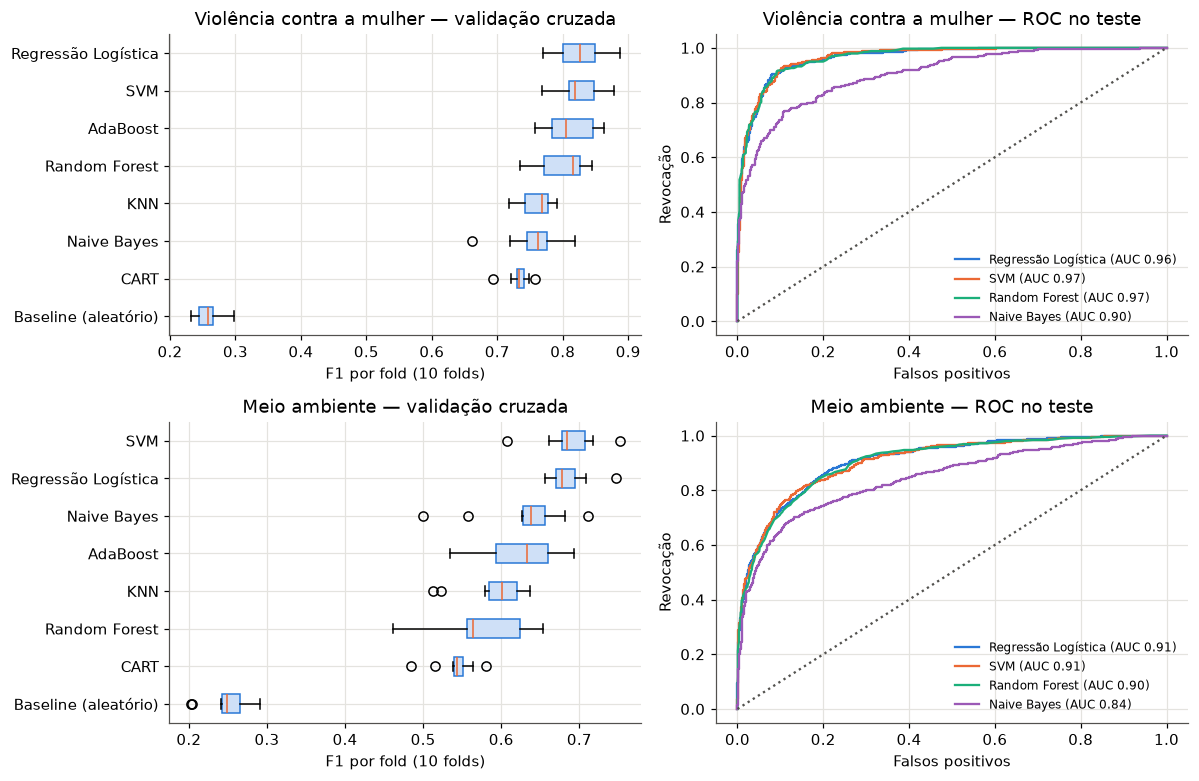

In [10]:
def fig_cv_roc(resultados, nome_arq):
    fig, axs = plt.subplots(len(resultados), 2, figsize=(11, 3.6 * len(resultados)))
    axs = np.atleast_2d(axs)
    for i, R in enumerate(resultados):
        ordem = [n for n in R["cv"].sort_values("f1_media").index]
        ax = axs[i, 0]
        ax.boxplot([R["cv_folds"][n] for n in ordem], vert=False, tick_labels=ordem, patch_artist=True,
                   boxprops=dict(facecolor="#cfe0f7", edgecolor=AZUL), medianprops=dict(color=LARANJA))
        ax.set_xlabel("F1 por fold (10 folds)"); ax.set_title(f"{R['tema']} — validação cruzada")
        ax = axs[i, 1]
        for n, cor in [("Regressão Logística", AZUL), ("SVM", LARANJA), ("Random Forest", VERDE), ("Naive Bayes", "#9b59b6")]:
            _, _, s = R["preds"][n]; fpr, tpr, _ = roc_curve(R["yt"], s)
            ax.plot(fpr, tpr, color=cor, label=f"{n} (AUC {roc_auc_score(R['yt'], s):.2f})")
        ax.plot([0, 1], [0, 1], color=TEXTO2, ls=":"); ax.set_xlabel("Falsos positivos"); ax.set_ylabel("Revocação")
        ax.set_title(f"{R['tema']} — ROC no teste"); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(DIR_FIG / (nome_arq + ".png")); fig.savefig(DIR_FIG / (nome_arq + ".pdf")); plt.show()
fig_cv_roc([R1, R2], "fig5_classificacao_cv_roc")

## 6. Análise do melhor modelo e dos erros
Para cada tema: matriz de confusão do melhor modelo (escolhido apenas pela validação cruzada), termos de maior peso (Regressão Logística) e revocação por período (deriva temporal).

In [11]:
def analisar(R, n_termos=15):
    nome = R["melhor"] + " (ajustado)"; pipe, pred, s = R["preds"][nome]
    a, tst, yt = R["amostra"], R["tst"], R["yt"]
    print(f"### {R['tema']} — melhor modelo pela CV: {nome}")
    print("Matriz de confusão (linhas = real, colunas = previsto):\n", confusion_matrix(yt, pred))
    # termos mais associados ao tema (regressão logística, não ajustada)
    lr, _, _ = R["preds"]["Regressão Logística"]
    nomes = lr.named_steps["tfidf"].get_feature_names_out()[lr.named_steps["selecao"].get_support()]
    coef = lr.named_steps["clf"].coef_[0]
    top = pd.Series(coef, index=nomes).sort_values(ascending=False)
    print("\nTermos que mais indicam o tema:", ", ".join(top.index[:n_termos]))
    print("Termos que mais indicam NÃO-tema:", ", ".join(top.index[-8:]))
    # revocação por período
    t = a.iloc[tst].assign(pred=pred, s=s)
    t["periodo"] = pd.cut(t["ano"].astype(float), [1993, 2003, 2013, 2024], labels=["1994–2003", "2004–2013", "2014–2024"])
    per = t[t.y == 1].groupby("periodo", observed=True).apply(lambda d: pd.Series({"positivos": len(d), "revocacao": d.pred.mean()}))
    print("\nRevocação por período:\n", per.round(3))
    return t

T1 = analisar(R1); print(); T2 = analisar(R2)

### Violência contra a mulher — melhor modelo pela CV: Regressão Logística (ajustado)
Matriz de confusão (linhas = real, colunas = previsto):
 [[934  92]
 [ 33 305]]

Termos que mais indicam o tema: mulheres, mulher, violencia, lei, obrigada, contra, senadora, feminina, direitos, vitimas, combate, senadoras, gente, vitima, protecao
Termos que mais indicam NÃO-tema: santa, ordem, cardoso, governador, regiao, henrique, partido, fernando

Revocação por período:
            positivos  revocacao
periodo                        
1994–2003       11.0      0.909
2004–2013      131.0      0.947
2014–2024      196.0      0.872

### Meio ambiente — melhor modelo pela CV: Regressão Logística (ajustado)
Matriz de confusão (linhas = real, colunas = previsto):
 [[1534  273]
 [ 126  482]]

Termos que mais indicam o tema: ambiental, amazonia, marina, ibama, preservacao, ambientais, floresta, agua, florestal, defesa, ministra, florestas, areas, fiscalizacao, amazonica
Termos que mais indicam NÃO-tema: da

In [12]:
# Falsos positivos de maior pontuação: discursos SEM termos da lista que o modelo considera do tema
def mostrar_fp(T, n=5):
    fp = T[(T.y == 0) & (T.pred == 1)].sort_values("s", ascending=False).head(n)
    for r in fp.itertuples():
        print(f"- {r.autor_nome} ({int(r.ano)}) {r.url}\n  {r.texto_limpo[:350]}...\n")
print("VCM — falsos positivos:"); mostrar_fp(T1)

VCM — falsos positivos:
- angela portela (2013) https://www25.senado.leg.br/web/atividade/pronunciamentos/-/p/texto/404742
  Sr. Presidente, Senador Mozarildo Cavalcanti, Srªs e Srs. Senadores, é com muita satisfação que quero registrar aqui, no plenário do Senado Federal, a nossa participação, nos dias 27, 28 e 29 de novembro, no Fórum Global - As mulheres nos Parlamentos, realizado em Bruxelas, na Bélgica, no Parlamento Europeu.
Eu gostaria de agradecer à nossa Procura...

- paulo paim (2011) https://www25.senado.leg.br/web/atividade/pronunciamentos/-/p/texto/386885
  Sr. Presidente, quero de pronto deixar registrado, nos Anais da Casa, um boletim editado pelo Ministério da Previdência, Previdência em Questão, de 28 de fevereiro de 2011, que diz: “Previdência urbana registra superávit de R$14, 9 bilhões, em 2010”.
Fico feliz, Sr. Presidente, porque, quando digo que a Previdência brasileira, a contributiva de emp...

- paulo paim (2013) https://www25.senado.leg.br/web/atividade/pronun

In [13]:
print("Meio ambiente — falsos positivos:"); mostrar_fp(T2)

Meio ambiente — falsos positivos:
- valdir raupp (2003) https://www25.senado.leg.br/web/atividade/pronunciamentos/-/p/texto/342487
  Sr. Presidente, Srªs e Srs. Senadores, a Constituição Federal, em seu art. 3º, estabelece os objetivos fundamentais da República Federativa do Brasil. Dentre os objetivos ali relacionados, gostaria, neste momento, de destacar dois: garantir o desenvolvimento nacional e reduzir as desigualdades sociais e regionais.
É com imensa satisfação que venho ...

- joao pedro (2008) https://www25.senado.leg.br/web/atividade/pronunciamentos/-/p/texto/374751
  Presidente Paulo Paim, Srs. Senadores, Srªs Senadoras, esta semana foi, sem dúvida, uma semana rica em conquistas, em avanços no campo da educação.
Quero lembrar aqui que, na reunião histórica na Comissão de Educação da última terça-feira, presidida pelo Senador Cristovam, dentre as várias matérias aprovadas, há duas matérias relevantes, históricas...

- casildo maldaner (2012) https://www25.senado.leg.br/web/at

## 7. Salvamento dos resultados e do modelo

In [14]:
def salvar(R, slug):
    R["cv"].round(4).to_csv(DIR_RES / f"{slug}_cv10.csv")
    R["teste"].round(4).to_csv(DIR_RES / f"{slug}_teste.csv")
    joblib.dump(R["preds"][R["melhor"] + " (ajustado)"][0], DIR_MOD / f"{slug}_melhor_modelo.joblib", compress=3)
salvar(R1, "vcm"); salvar(R2, "meio_ambiente")
resumo = {R["tema"]: {"n_amostra": int(len(R["amostra"])), "n_positivos": int(R["amostra"].y.sum()),
          "n_teste": int(len(R["tst"])), "melhor_modelo_cv": R["melhor"],
          "melhor_params": R["teste"].loc[R["melhor"] + " (ajustado)", "params"],
          "cv_f1_melhor": float(R["ajust"][R["melhor"]].best_score_),
          "teste_melhor": R["teste"].loc[R["melhor"] + " (ajustado)", ["f1", "precisao", "revocacao", "auc", "acuracia"]].astype(float).round(4).to_dict()}
          for R in (R1, R2)}
(DIR_RES / "resumo_classificacao.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(resumo, ensure_ascii=False, indent=2))

{
  "Violência contra a mulher": {
    "n_amostra": 6872,
    "n_positivos": 1718,
    "n_teste": 1364,
    "melhor_modelo_cv": "Regressão Logística",
    "melhor_params": "{'clf__C': 1, 'selecao__k': 5000}",
    "cv_f1_melhor": 0.8296789525057362,
    "teste_melhor": {
      "f1": 0.8299,
      "precisao": 0.7683,
      "revocacao": 0.9024,
      "auc": 0.9654,
      "acuracia": 0.9084
    }
  },
  "Meio ambiente": {
    "n_amostra": 12000,
    "n_positivos": 3000,
    "n_teste": 2415,
    "melhor_modelo_cv": "Regressão Logística",
    "melhor_params": "{'clf__C': 1, 'selecao__k': 5000}",
    "cv_f1_melhor": 0.693431000908904,
    "teste_melhor": {
      "f1": 0.7073,
      "precisao": 0.6384,
      "revocacao": 0.7928,
      "auc": 0.9088,
      "acuracia": 0.8348
    }
  }
}
